# 02 - EDA & visualization - all three datasets

**Goal:** understand each dataset well enough to make modeling decisions, and produce
the plots that will carry the project's story. Every section ends with a findings box;
those bullets become the README insights later.

What each lens needs answered here:
- **A/B (Telco):** what separates churners, and *when* do they leave?
- **D:** which human-readable groups exist (profiling now, clustering in 03)?
- **E (Retail):** is there repeat-purchase structure worth a CLV model?
- **C (MegaFon):** is the experiment balanced, and what is the *naive* treatment effect
  that uplift modeling will refine?

Note the imports: this notebook writes **zero loading code** - that is notebook 01's
promoted API at work.

In [17]:
import sys
from pathlib import Path

# Make src/ importable whether Jupyter starts in the project root or in Code/
for candidate in (Path.cwd(), Path.cwd() / "Code", Path.cwd().parent):
    if (candidate / "phase_1").exists():
        sys.path.insert(0, str(candidate))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)

from phase_1.loader import load_telco, load_retail, load_megafon
from phase_1 import eda
from phase_1.preprocessing import rfm_table

eda.set_style()
telco = load_telco()
retail = load_retail()
mega = load_megafon()
print(f"telco {telco.shape} - retail {retail.shape} - megafon {mega.shape}")

telco (7043, 21) - retail (779425, 10) - megafon (600000, 52)


## 1. Telco - the target, and the accuracy trap

26.5% churn. Burn this number in: a model that predicts "nobody churns" is **73.5%
accurate and 100% useless**. Everything downstream is therefore judged on ranking
metrics (ROC-AUC, PR-AUC), recall, and lift - never accuracy.

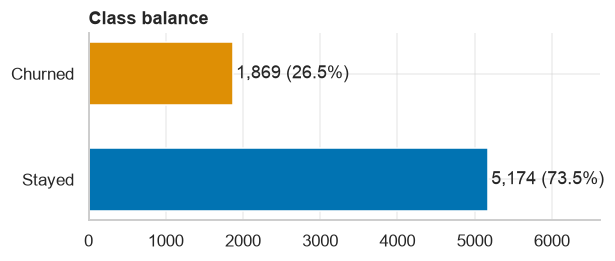

In [18]:
rate = telco["Churn"].mean()
counts = telco["Churn"].value_counts()
fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(["Stayed", "Churned"], [counts[0], counts[1]], color=[eda.PALETTE[0], eda.PALETTE[1]], height=0.6)
for i, v in enumerate([counts[0], counts[1]]):
    ax.text(v + 40, i, f"{v:,} ({v/len(telco):.1%})", va="center")
ax.set_xlim(0, counts[0] * 1.28)
ax.set_title("Class balance")
plt.show()

### 1.1 Numeric features by outcome

`tenure` is the story: churners mass at the very start of the customer lifecycle
(the distribution is close to bimodal for stayers - a loyal long-tenure hump - while
churners pile up under 10 months). `MonthlyCharges` adds: churners skew expensive.

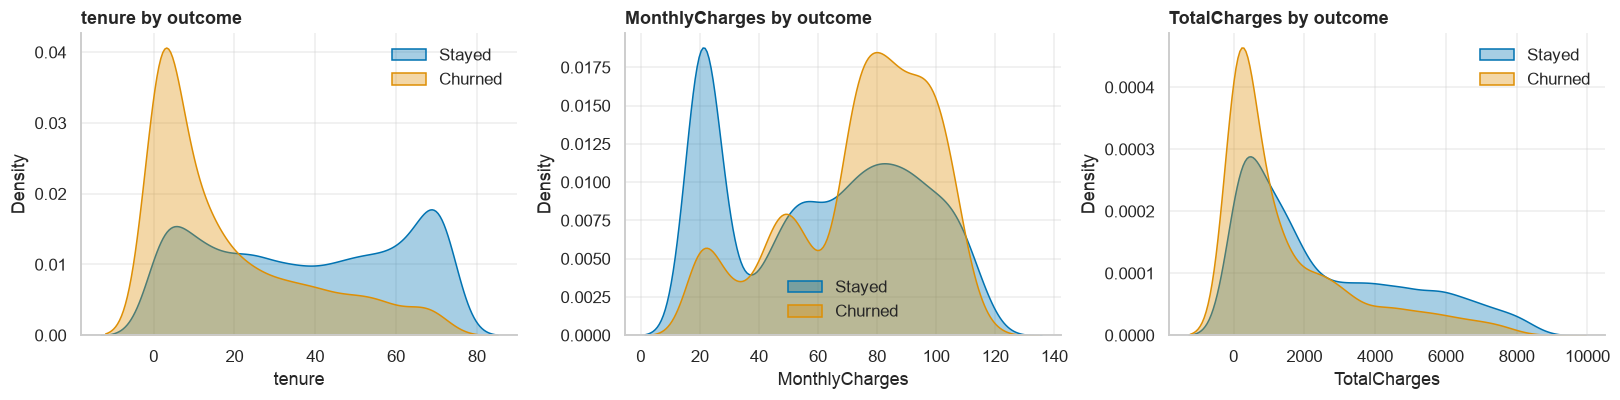

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    eda.plot_dist_by_target(telco, col, ax=ax)
plt.tight_layout()
plt.show()

### 1.2 Categorical churn rates - where the risk lives

Four views, one message: **commitment and support are protective**. Month-to-month
contracts, electronic-check payment, fiber internet (price-sensitive, competitive
market) and no tech support are the risk quadrant.

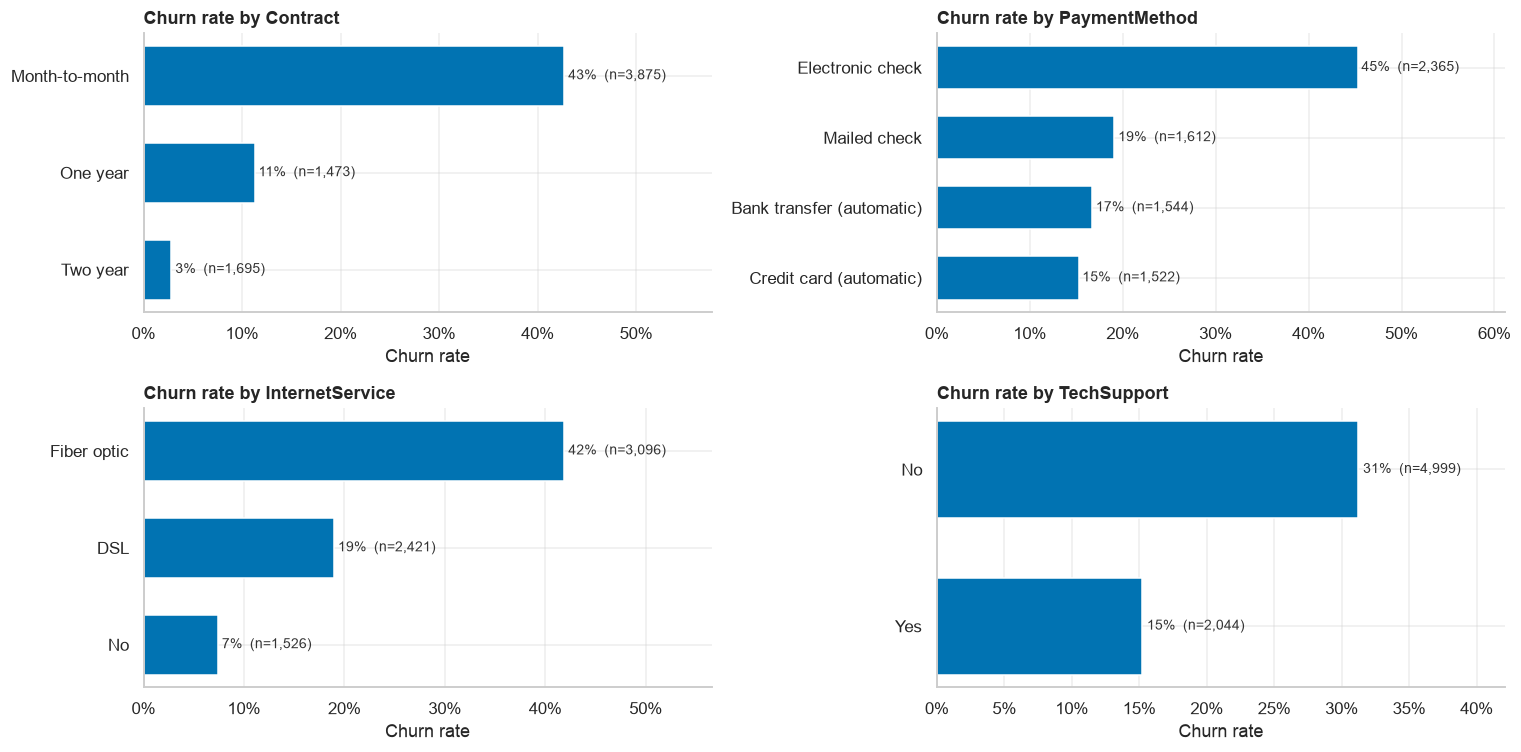

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
for ax, col in zip(axes.flat, ["Contract", "PaymentMethod", "InternetService", "TechSupport"]):
    eda.plot_rate_by_category(telco, col, ax=ax)
plt.tight_layout()
plt.show()

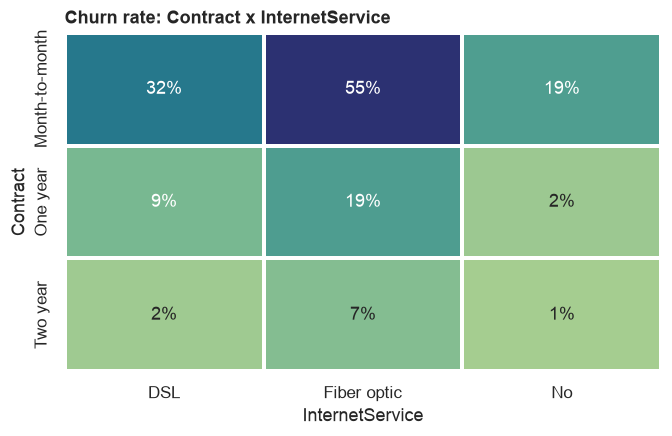

In [21]:
eda.crosstab_heatmap(telco, "Contract", "InternetService")
plt.show()

### 1.3 When do churners leave? (survival preview)

Cumulative share of each contract group's churners gone by month *m*. Month-to-month
churn is brutally front-loaded - this is the empirical case for Lens B and for
onboarding-window retention offers.

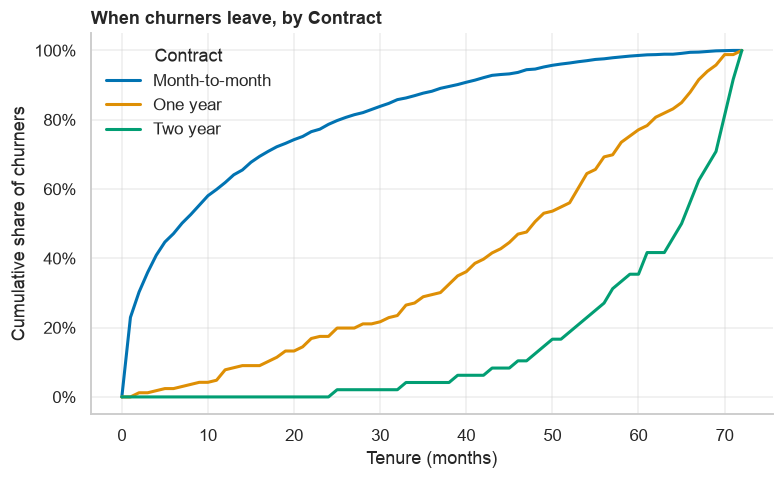

In [22]:
eda.cumulative_churn_by_tenure(telco, "Contract")
plt.show()

### 1.4 Correlations + a multicollinearity decision

`TotalCharges ~ tenure x MonthlyCharges` (r ~ 0.83 with tenure). Decision, recorded
here: **keep it for tree models** (they don't care), **drop it for the survival
model** (it secretly encodes the duration outcome - see `features.encode_for_survival`).

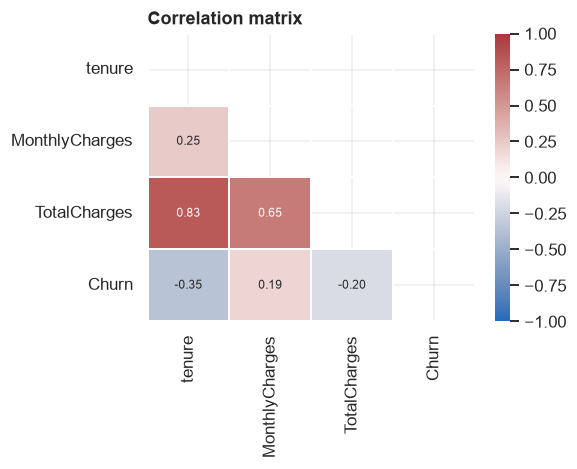

In [23]:
eda.corr_heatmap(telco[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]])
plt.show()

### 1.5 Segmentation-flavored profiling - the danger-zone table

Before any clustering: just group by demographics and read the churn rates. This
table is Lens D's "ground truth for sanity" - clusters that contradict it need a
very good excuse.

In [24]:
profile = eda.churn_profile_table(telco, ["SeniorCitizen", "Partner", "Dependents"])
profile.head(8)

,SeniorCitizen,Partner,Dependents,rate,n
0,Yes,No,No,0.492,561
1,Yes,Yes,No,0.363,490
2,No,No,No,0.312,2719
3,Yes,No,Yes,0.250,8
4,Yes,Yes,Yes,0.241,83
5,No,No,Yes,0.212,353
6,No,Yes,No,0.208,1163
7,No,Yes,Yes,0.137,1666


In [25]:
contract_profile = eda.churn_profile_table(telco, ["Contract", "InternetService", "TechSupport"])
contract_profile.head(8)

,Contract,InternetService,TechSupport,rate,n
0,Month-to-month,Fiber optic,No,0.575,1796
1,Month-to-month,Fiber optic,Yes,0.389,332
2,Month-to-month,DSL,No,0.359,884
3,Month-to-month,DSL,Yes,0.227,339
4,One year,Fiber optic,Yes,0.204,226
5,Month-to-month,No,No,0.189,524
6,One year,Fiber optic,No,0.185,313
7,One year,DSL,No,0.098,244


> **Telco findings**
> 1. 26.5% base churn -> accuracy is off the table as a metric.
> 2. Churn is front-loaded: the first year is the danger window.
> 3. Month-to-month + fiber + electronic check + no tech support ~ 55-70% churn pockets.
> 4. Two-year contracts churn at ~3% - commitment is the strongest lever the business owns.
> 5. `TotalCharges` is collinear with tenure - dropped for survival, kept for trees.
> 6. Seniors without partners/dependents churn well above base - a demographic slice
>    worth its own retention track.

## 2. Online Retail II - repeat-purchase structure

Non-contractual commerce: nobody "cancels", they just stop showing up. So the churn
evidence must come from **behavior over time** - which is exactly what the cohort
heatmap shows.

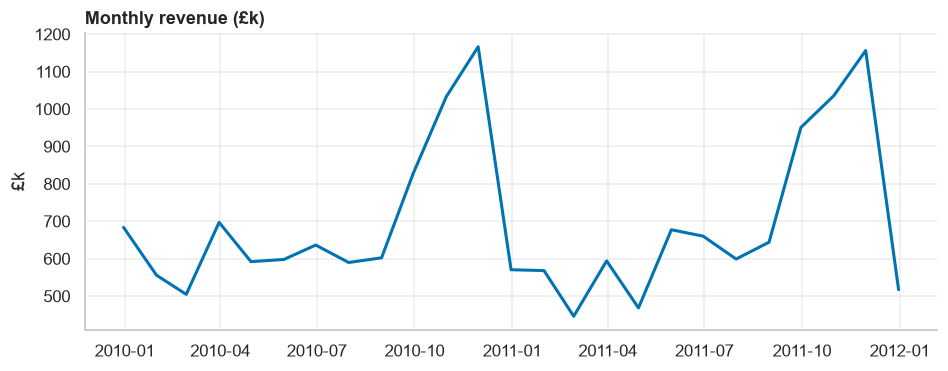

In [26]:
monthly = retail.set_index("InvoiceDate").resample("ME").agg(
    revenue=("Revenue", "sum"), orders=("Invoice", "nunique"))
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(monthly.index, monthly["revenue"] / 1000, color=eda.PALETTE[0], linewidth=2)
ax.set_title("Monthly revenue (£k)")
ax.set_ylabel("£k")
plt.show()

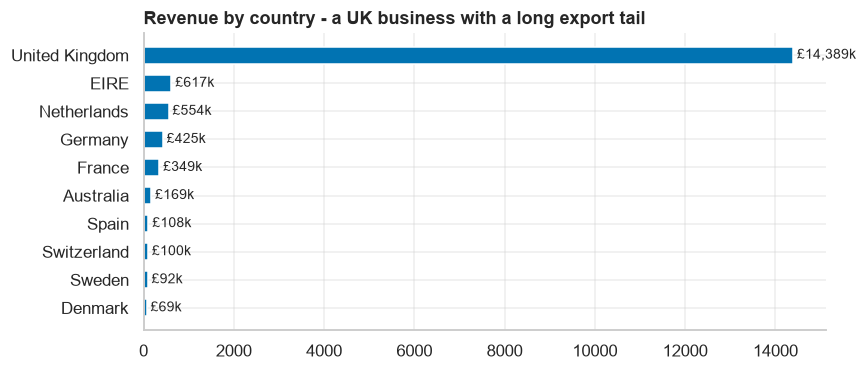

In [27]:
top_countries = (retail.groupby("Country")["Revenue"].sum()
                 .sort_values(ascending=False).head(10) / 1000)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(top_countries.index[::-1], top_countries.values[::-1], color=eda.PALETTE[0], height=0.6)
for i, v in enumerate(top_countries.values[::-1]):
    ax.text(v, i, f" £{v:,.0f}k", va="center", fontsize=9)
ax.set_title("Revenue by country - a UK business with a long export tail")
plt.show()

### 2.1 RFM distributions

All three are heavily right-skewed (most customers buy once or twice; a whale tail
buys constantly). This motivates the quantile scoring in `features.rfm_table` and the
log transforms before clustering in 03.

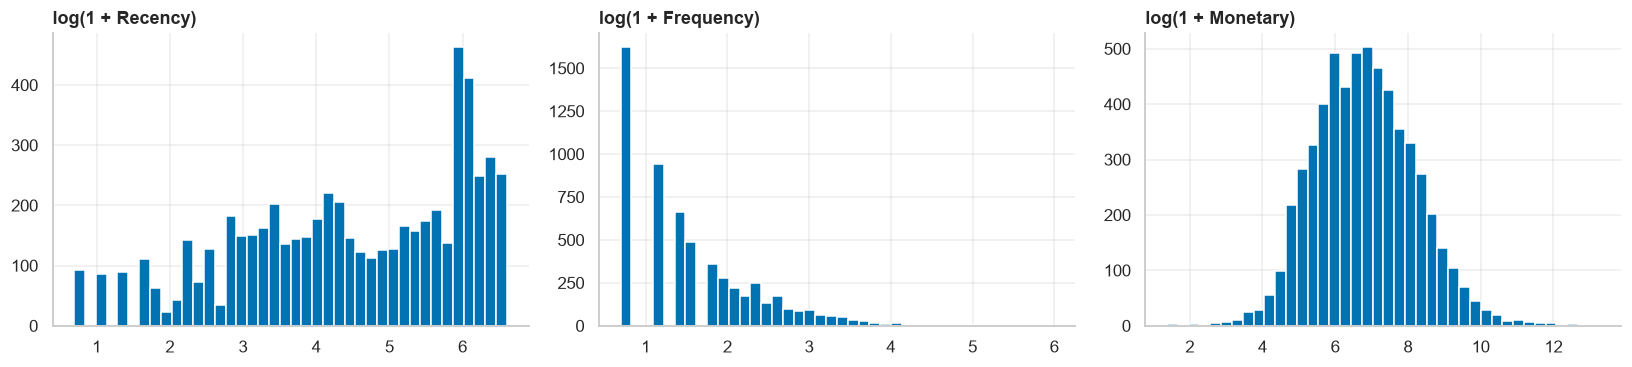

segment
Hibernating        1526
Champions          1473
Regular            1089
Loyal               878
At risk             471
New / promising     441
Name: count, dtype: int64

In [28]:
rfm = rfm_table(retail)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    ax.hist(np.log1p(rfm[col]), bins=40, color=eda.PALETTE[0])
    ax.set_title(f"log(1 + {col})")
plt.tight_layout()
plt.show()
rfm["segment"].value_counts()

### 2.2 Cohort retention - the plot that justifies the whole project

Each row is an acquisition month; each column, months since first purchase; each cell,
the share still buying. Read any row left to right: **the cliff after month 0 is
churn**, visible without any label ever existing.

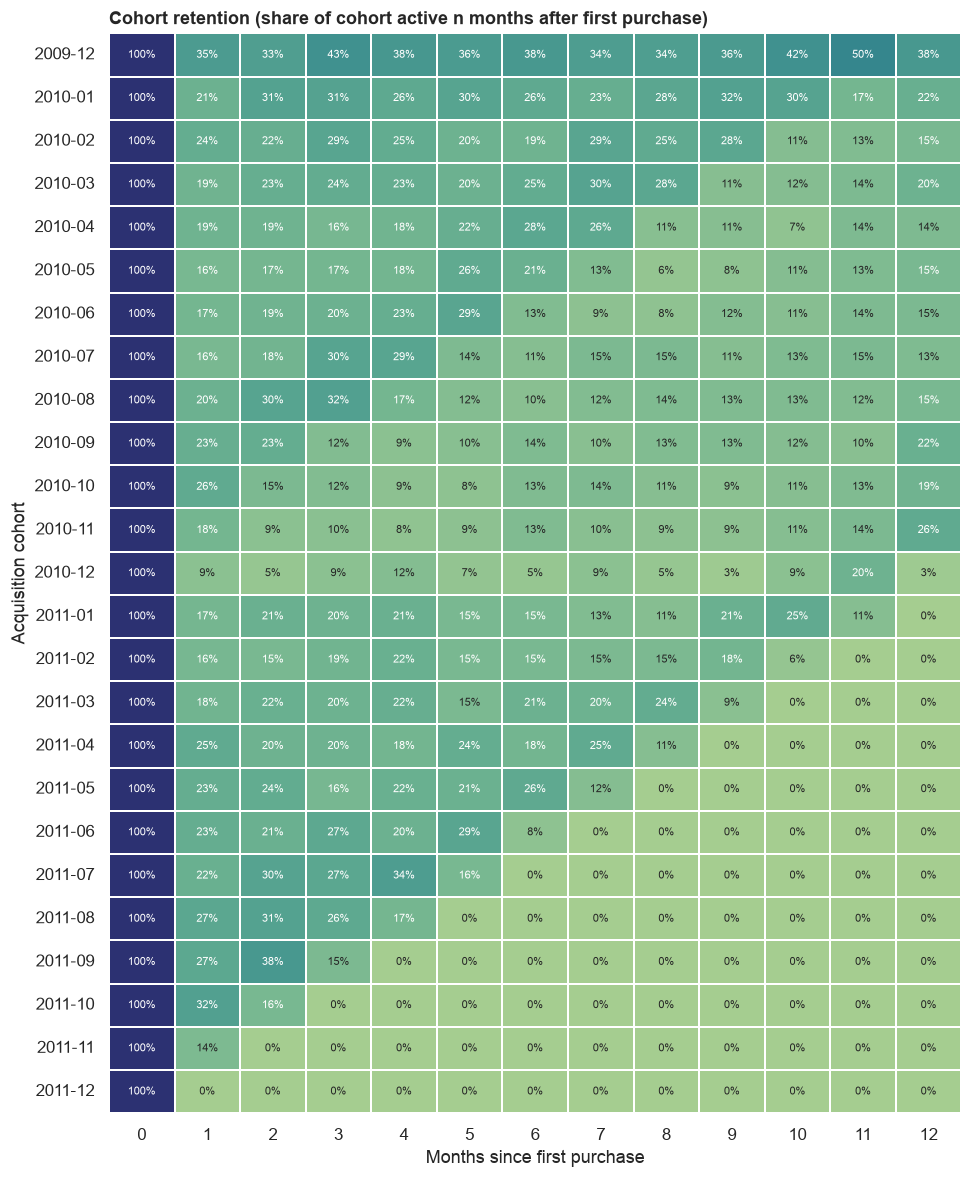

median 1-month retention: 20%   median 6-month retention: 13%


In [29]:
ax, retention = eda.cohort_retention_heatmap(retail)
plt.show()
print(f"median 1-month retention: {retention[1].median():.0%}   "
      f"median 6-month retention: {retention[6].median():.0%}")

> **Retail findings**
> 1. Typical cohort: **~20-25% still buying one month after first purchase** - the
>    non-contractual churn cliff is real and steep.
> 2. Revenue is whale-driven: the top RFM quintile carries most of the money -
>    losing one "Champion" != losing one average customer, which is why Lens E
>    (CLV) must weight churn risk by customer value.
> 3. Strong seasonality (Nov-Dec peaks) - any time-split validation must respect it.
> 4. ~1 in 4 rows has no CustomerID (guest checkout) - customer-level analysis covers
>    the identified majority only; stated as a known limitation.

## 3. MegaFon - is the experiment healthy?

Uplift modeling stands on one assumption: **treatment was randomized**. Two checks:
group sizes/conversion (the naive effect), and whether feature distributions match
across groups (they must - the campaign was assigned, not chosen).

In [30]:
report = eda.treatment_balance_report(mega)
report

Naive average treatment effect: +0.0495 (0.2289 vs 0.1794)


,treatment_group,n,conversions,conversion_rate
0,control,299632,53754,0.179400
1,treatment,300368,68760,0.228919


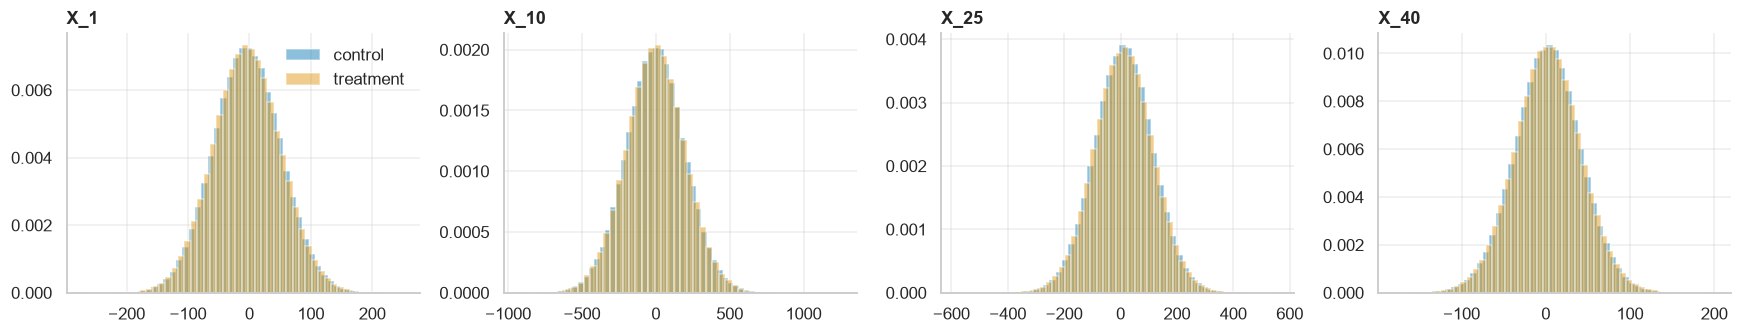

In [31]:
check_cols = ["X_1", "X_10", "X_25", "X_40"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, col in zip(axes, check_cols):
    for grp, color in zip(["control", "treatment"], eda.PALETTE[:2]):
        sub = mega.loc[mega["treatment_group"] == grp, col]
        ax.hist(sub, bins=50, alpha=0.45, density=True, color=color, label=grp)
    ax.set_title(col)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

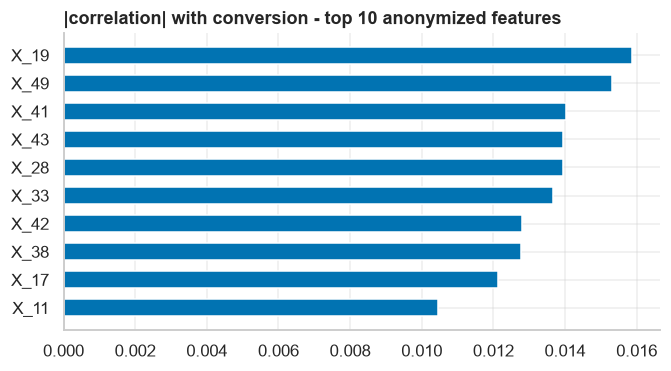

In [32]:
feature_cols = [c for c in mega.columns if c.startswith("X_")]
corr = (mega[feature_cols].corrwith(mega["conversion"]).abs()
        .sort_values(ascending=False).head(10))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(corr.index[::-1], corr.values[::-1], color=eda.PALETTE[0], height=0.6)
ax.set_title("|correlation| with conversion - top 10 anonymized features")
plt.show()

> **MegaFon findings**
> 1. Treatment/control distributions overlap -> randomization looks credible.
> 2. The naive average treatment effect (treated conversion - control conversion) is
>    positive but small - the campaign works *on average*. Lens C's job is to find
>    the customers for whom it works *a lot*, and skip the rest.
> 3. Features are anonymized, so Lens C will be judged purely on Qini/uplift metrics,
>    not interpretability - set that expectation now.

## Promoted to `phase_1/`

`plot_rate_by_category`, `plot_dist_by_target`, `crosstab_heatmap`, `corr_heatmap`,
`cumulative_churn_by_tenure`, `churn_profile_table`, `cohort_retention_heatmap`,
`treatment_balance_report` -> **`phase_1/visualization/eda.py`** (plus the validated 5-color palette and
style). `rfm_table` sits in **`phase_1/preprocessing/features.py`** because 03 reuses it for modeling.

**Next:** `03_feature_engineering_modeling.ipynb` - five lenses, five targets, one
leakage rule.